# Word Embedding Layer in Keras

Convert words into numbers, make every sentence the same length, then turn every word into a dense vector with an `Embedding` layer.

Tested with **TensorFlow 2.21** (Keras 3).

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization, Embedding, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import pad_sequences

print(tf.__version__)

2.21.0


## 1. Our sentences

In [2]:
sentences = [
    'a cup of chai',
    'a cup of coffee',
    'a plate of samosa',
    'I love playing cricket',
    'I love watching cricket',
    'learn the meaning of words',
    'this biryani tastes amazing',
]
sentences

['a cup of chai',
 'a cup of coffee',
 'a plate of samosa',
 'I love playing cricket',
 'I love watching cricket',
 'learn the meaning of words',
 'this biryani tastes amazing']

## 2. Words to numbers with `TextVectorization`

`TextVectorization` builds a vocabulary from our sentences with `adapt()`.
Every word gets a fixed number (its index). Index **0** is kept for padding and index **1** for unknown words (`[UNK]`).

In [3]:
voc_size = 10000

vectorizer = TextVectorization(max_tokens=voc_size)
vectorizer.adapt(sentences)

vocab = [str(w) for w in vectorizer.get_vocabulary()]
print(len(vocab), 'words in the vocabulary')
print(vocab)   # position of a word in this list = its number

22 words in the vocabulary
['', '[UNK]', 'of', 'a', 'love', 'i', 'cup', 'cricket', 'words', 'watching', 'this', 'the', 'tastes', 'samosa', 'playing', 'plate', 'meaning', 'learn', 'coffee', 'chai', 'biryani', 'amazing']


In [4]:
word_ids = [vectorizer(s).numpy().tolist() for s in sentences]
word_ids

[[3, 6, 2, 19],
 [3, 6, 2, 18],
 [3, 15, 2, 13],
 [5, 4, 14, 7],
 [5, 4, 9, 7],
 [17, 11, 16, 2, 8],
 [10, 20, 12, 21]]

Notice: `a cup of chai` and `a cup of coffee` share the first three numbers. Only the last word is different.
Run the cell again: the numbers stay the same every time.

## 3. Make every sentence the same length with `pad_sequences`

An RNN reads a fixed number of time steps, so every sentence must have the same number of words.
`padding='pre'` adds zeros at the start, `padding='post'` adds them at the end.

In [5]:
sent_length = 8

padded = pad_sequences(word_ids, padding='pre', maxlen=sent_length)
print(padded)

[[ 0  0  0  0  3  6  2 19]
 [ 0  0  0  0  3  6  2 18]
 [ 0  0  0  0  3 15  2 13]
 [ 0  0  0  0  5  4 14  7]
 [ 0  0  0  0  5  4  9  7]
 [ 0  0  0 17 11 16  2  8]
 [ 0  0  0  0 10 20 12 21]]


In [6]:
print(pad_sequences(word_ids, padding='post', maxlen=sent_length))

[[ 3  6  2 19  0  0  0  0]
 [ 3  6  2 18  0  0  0  0]
 [ 3 15  2 13  0  0  0  0]
 [ 5  4 14  7  0  0  0  0]
 [ 5  4  9  7  0  0  0  0]
 [17 11 16  2  8  0  0  0]
 [10 20 12 21  0  0  0  0]]


## 4. The Embedding layer

Two important numbers:
* `voc_size`: how many words the layer knows (rows of its table)
* `dim`: how many numbers (features) describe each word (columns)

In [7]:
dim = 10

model = Sequential([
    Input(shape=(sent_length,)),
    Embedding(input_dim=voc_size, output_dim=dim),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 8, 10)          │       100,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,000 (390.62 KB)

 Trainable params: 100,000 (390.62 KB)

 Non-trainable params: 0 (0.00 B)

Parameters = 10,000 words x 10 numbers = **100,000**. The layer is just a big table: one row of 10 numbers for every word.

In [8]:
vectors = model.predict(padded, verbose=0)
print(vectors)
print(vectors.shape)   # (sentences, words per sentence, numbers per word)

[[[-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152
   -0.02174677  0.03940162  0.04844085 -0.00418133 -0.02132875]
  [-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152
   -0.02174677  0.03940162  0.04844085 -0.00418133 -0.02132875]
  [-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152
   -0.02174677  0.03940162  0.04844085 -0.00418133 -0.02132875]
  [-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152
   -0.02174677  0.03940162  0.04844085 -0.00418133 -0.02132875]
  [-0.01775745  0.02661461 -0.03232088 -0.04741659 -0.00279347
    0.04076064  0.00098946  0.01181597 -0.03910857  0.01413545]
  [-0.01258301 -0.04620251  0.03076671  0.03505138  0.02566283
   -0.01118527 -0.01190022  0.01175827  0.00909704 -0.03673626]
  [ 0.04270191  0.04183272  0.04800812 -0.02319465 -0.04617791
   -0.04237185  0.0315166  -0.01098387 -0.01673717  0.01064434]
  [-0.02266799 -0.02714338 -0.01062902 -0.0254343  -0.02030145
   -0.02462223 -0.02921652  0.00043305  0.023888

In [9]:
print(padded[0])
print(vectors[0], 3)

[ 0  0  0  0  3  6  2 19]
[[-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152 -0.02174677
   0.03940162  0.04844085 -0.00418133 -0.02132875]
 [-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152 -0.02174677
   0.03940162  0.04844085 -0.00418133 -0.02132875]
 [-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152 -0.02174677
   0.03940162  0.04844085 -0.00418133 -0.02132875]
 [-0.04141703 -0.045849    0.0371995   0.00229336  0.00036152 -0.02174677
   0.03940162  0.04844085 -0.00418133 -0.02132875]
 [-0.01775745  0.02661461 -0.03232088 -0.04741659 -0.00279347  0.04076064
   0.00098946  0.01181597 -0.03910857  0.01413545]
 [-0.01258301 -0.04620251  0.03076671  0.03505138  0.02566283 -0.01118527
  -0.01190022  0.01175827  0.00909704 -0.03673626]
 [ 0.04270191  0.04183272  0.04800812 -0.02319465 -0.04617791 -0.04237185
   0.0315166  -0.01098387 -0.01673717  0.01064434]
 [-0.02266799 -0.02714338 -0.01062902 -0.0254343  -0.02030145 -0.02462223
  -0.02921652  0.00043305

In [10]:
# same word = same row of the table = same vector
cup_id = vocab.index('cup')
print('cup in sentence 1:', vectors[0][5], 3)
print('cup in sentence 2:', vectors[1][5], 3)
print('row', cup_id, 'of the table:', model.layers[0].get_weights()[0][cup_id], 3)   # get_weights()[0] is the embedding table

cup in sentence 1: [-0.01258301 -0.04620251  0.03076671  0.03505138  0.02566283 -0.01118527
 -0.01190022  0.01175827  0.00909704 -0.03673626] 3
cup in sentence 2: [-0.01258301 -0.04620251  0.03076671  0.03505138  0.02566283 -0.01118527
 -0.01190022  0.01175827  0.00909704 -0.03673626] 3
row 6 of the table: [-0.01258301 -0.04620251  0.03076671  0.03505138  0.02566283 -0.01118527
 -0.01190022  0.01175827  0.00909704 -0.03673626] 3


## 5. Optional: what trained word vectors look like

Pretrained GloVe vectors (50 numbers per word), squeezed to 2D with PCA. Similar words land close together.

Needs `pip install gensim scikit-learn matplotlib` and downloads about 66 MB once.

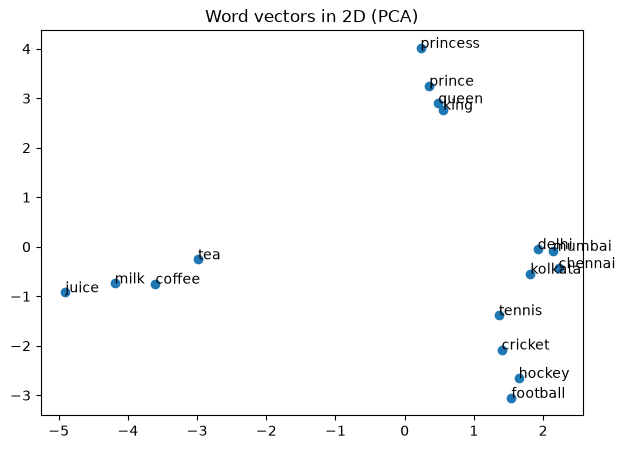

tea vs coffee : 0.8079648
tea vs cricket: 0.45997888


In [ ]:
import gensim.downloader as api
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

glove = api.load('glove-wiki-gigaword-50')

words = ['tea', 'coffee', 'milk', 'juice',
         'cricket', 'football', 'hockey', 'tennis',
         'mumbai', 'delhi', 'chennai', 'kolkata',
         'king', 'queen', 'prince', 'princess']
points = PCA(n_components=2).fit_transform(np.array([glove[w] for w in words]))

plt.figure(figsize=(7, 5))
plt.scatter(points[:, 0], points[:, 1])
for w, (x, y) in zip(words, points):
    plt.annotate(w, (x, y))
plt.title('Word vectors in 2D (PCA)')
plt.show()

# closer to 1 means more similar meaning
print('tea vs coffee :', glove.similarity('tea', 'coffee'))
print('tea vs cricket:', glove.similarity('tea', 'cricket'))